In [ ]:
import numpy as np

# p of success aka clicking link
p = 0.30

# given 20 customers
sample_size = 20

# generate outcomes for 20 customers using np.random.binomial
# n=1 indicates a single Bernoulli trial for each customer
samples = np.random.binomial(n=1, p=p, size=sample_size)

print(f"Generated samples: ",samples)

Generated samples:  [0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0 1 0]


In [ ]:
# we generated for 20 customers
num_observations = len(samples)
print(f"Number of observations generated: {num_observations}")

Number of observations generated: 20


Step 4: Count clicks and non-clicks

In [ ]:
number_of_clicks = np.sum(samples == 1)
number_of_non_clicks = np.sum(samples == 0)

print("Number of clicks:", number_of_clicks)
print("Number of non-clicks:", number_of_non_clicks)

Number of clicks: 4
Number of non-clicks: 16


Step 5: Calculate the empirical PMF

In [ ]:
# Calculate empirical probabilities
empirical_p_1 = number_of_clicks / sample_size
empirical_p_0 = number_of_non_clicks / sample_size

print(f"Empirical P(X=1) (click): {empirical_p_1:.2f}")
print(f"Empirical P(X=0) (non-click): {empirical_p_0:.2f}")

Empirical P(X=1) (click): 0.20
Empirical P(X=0) (non-click): 0.80


Step 7: Plot empirical and theoretical PMFs

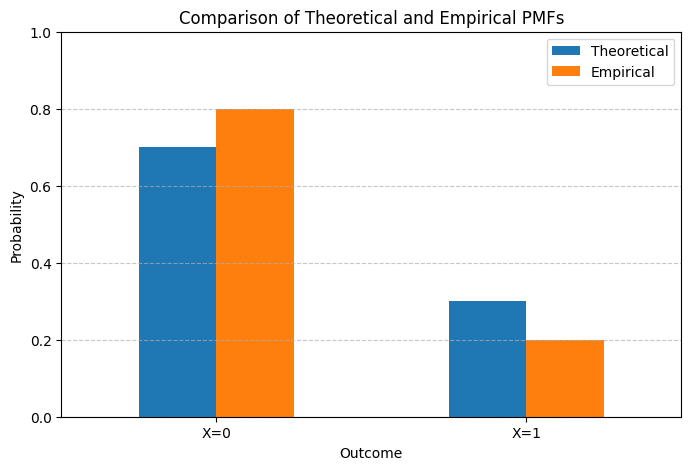

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Theoretical PMF
theoretical_pmf = {'X=0': 1 - p, 'X=1': p}

# Empirical PMF
empirical_pmf = {'X=0': empirical_p_0, 'X=1': empirical_p_1}

df_pmf = pd.DataFrame({
    'Outcome': ['X=0', 'X=1'],
    'Theoretical': [theoretical_pmf['X=0'], theoretical_pmf['X=1']],
    'Empirical': [empirical_pmf['X=0'], empirical_pmf['X=1']]
})

df_pmf.set_index('Outcome').plot(kind='bar', figsize=(8, 5))
plt.title('Comparison of Theoretical and Empirical PMFs')
plt.ylabel('Probability')
plt.ylim(0, 1) # Probabilities are between 0 and 1
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Step 8: Calculate the theoretical expectation

In [ ]:
# For a Bernoulli distribution, E[X] = p
theoretical_expectation = p
print(f"Theoretical Expectation (E[X]): {theoretical_expectation:.2f}")

Theoretical Expectation (E[X]): 0.30


Step 9: Calculate the empirical expectation

In [ ]:
# Empirical expectation is the mean of the samples
empirical_expectation = np.mean(samples)
print(f"Empirical Expectation (mean of samples): {empirical_expectation:.2f}")

Empirical Expectation (mean of samples): 0.20


Step 10: Calculate the theoretical variance

In [ ]:
# For a Bernoulli distribution, Var[X] = p * (1-p)
print(p)
theoretical_variance = p * (1 - p)
print(f"Theoretical Variance (Var[X]): {theoretical_variance:.2f}")

0.3
Theoretical Variance (Var[X]): 0.21


Step 11: Calculate the empirical variance

In [ ]:
# Empirical variance of the samples
empirical_variance = np.var(samples)
print(f"Empirical Variance: {empirical_variance:.2f}")

Empirical Variance: 0.16


Step 12: Prepare the final result table

In [ ]:
# Calculate absolute differences
absolute_diff_p0 = abs(theoretical_pmf['X=0'] - empirical_pmf['X=0'])
absolute_diff_p1 = abs(theoretical_pmf['X=1'] - empirical_pmf['X=1'])
absolute_diff_expectation = abs(theoretical_expectation - empirical_expectation)
absolute_diff_variance = abs(theoretical_variance - empirical_variance)

# Create a dictionary for the table
results_table_data = {
    'Measure': ['P(X=0)', 'P(X=1)', 'Expectation', 'Variance'],
    'Theoretical Value': [theoretical_pmf['X=0'], theoretical_pmf['X=1'], theoretical_expectation, theoretical_variance],
    'Empirical Value': [empirical_pmf['X=0'], empirical_pmf['X=1'], empirical_expectation, empirical_variance],
    'Absolute Difference': [absolute_diff_p0, absolute_diff_p1, absolute_diff_expectation, absolute_diff_variance]
}

# Create DataFrame and display
results_df = pd.DataFrame(results_table_data)
display(results_df.round(2))

,Measure,Theoretical Value,Empirical Value,Absolute Difference
0,P(X=0),0.70,0.80,0.10
1,P(X=1),0.30,0.20,0.10
2,Expectation,0.30,0.20,0.10
3,Variance,0.21,0.16,0.05


Step 13: Check Effect of sample size, Repeat the experiment n=10, 100, 1,000, 10,000

In [ ]:
sample_sizes = [10, 100, 1000, 10000]

# Store results in a list of dictionaries
experiment_results = []

for size in sample_sizes:
    # Generate new samples for the current sample size
    current_samples = np.random.binomial(n=1, p=p, size=size)

    # Count clicks and non-clicks
    current_clicks = np.sum(current_samples == 1)
    current_non_clicks = np.sum(current_samples == 0)

    # Calculate empirical probabilities
    current_empirical_p0 = current_non_clicks / size
    current_empirical_p1 = current_clicks / size

    # Calculate empirical mean and variance
    current_empirical_mean = np.mean(current_samples)
    current_empirical_variance = np.var(current_samples)

    # Append results
    experiment_results.append({
        'Sample size': size,
        'Empirical P(X=0)': current_empirical_p0,
        'Empirical P(X=1)': current_empirical_p1,
        'Empirical mean': current_empirical_mean,
        'Empirical variance': current_empirical_variance
    })

# Convert to DataFrame and display
sample_size_df = pd.DataFrame(experiment_results)
display(sample_size_df.round(3))

,Sample size,Empirical P(X=0),Empirical P(X=1),Empirical mean,Empirical variance
0,10,0.800,0.200,0.200,0.160
1,100,0.650,0.350,0.350,0.227
2,1000,0.684,0.316,0.316,0.216
3,10000,0.700,0.300,0.300,0.210
